In [1]:
import geopandas as gpd
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

In [2]:
gdf_DZ22_results = gpd.read_file("Prepared data for regression/Kintore-Tealing-DZ22-X_Y.geojson")
gdf_DZ22_results = gdf_DZ22_results.set_index("outputAreaCode")
gdf_DZ22_results.sample(10)

,pop_total,area_sqkm,density_pop/sqkm,distance_to_route,DZ22_Name,IZ22_Name,LA_Name,UR22_8FOLD_MIN,p_children,mean_adult_age,...,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,cumulativeActivity,modelled_per_100,empirical,empirical_per_100,geometry
outputAreaCode,,,,,,,,,,,,,,,,,,,,,
S01014246,850,16.206696,52.447458,6687.988375,Friockheim - 01,Friockheim,Angus,6,0.141190,57.536685,...,0.401070,0.459459,0.008226,0.827175,0.520942,0.034219,0.004026,1.0,0.117647,"POLYGON ((353376.999 751084, 353383 751681, 35..."
S01015498,924,0.186040,4966.681488,4023.637571,Downfield - 05,Downfield,Dundee City,1,0.238967,53.739745,...,0.240572,0.454545,0.029947,0.680600,0.479695,1.173930,0.127049,0.0,0.000000,"POLYGON ((338533 733460, 338421.795 733474.856..."
S01015366,558,0.052188,10692.173077,8068.174831,Perth Road - 01,Perth Road,Dundee City,1,0.109890,42.794239,...,0.318868,0.383094,0.079137,0.337165,0.275720,0.142690,0.025572,0.0,0.000000,"POLYGON ((339250.945 729547.232, 339262.198 72..."
S01015490,945,0.155385,6081.677209,4109.511730,Kirkton - 03,Kirkton,Dundee City,1,0.332272,46.290938,...,0.117647,0.378178,0.032839,0.222694,0.408360,0.495575,0.052442,0.0,0.000000,"POLYGON ((339983 733593, 339985 733568, 340000..."
S01013905,846,1.427379,592.694642,3932.645965,Inverurie South - 02,Inverurie South,Aberdeenshire,2,0.223502,49.333828,...,0.248521,0.374704,0.022459,0.520047,0.543307,0.773346,0.091412,0.0,0.000000,"POLYGON ((378137.493 820044.691, 378334.343 82..."
S01015543,900,0.142248,6326.965903,3717.983200,Ardler and St Marys - 07,Ardler and St Marys,Dundee City,1,0.298109,47.489699,...,0.161004,0.330367,0.011123,0.377778,0.425068,1.049671,0.116630,0.0,0.000000,"POLYGON ((337574.355 734104.439, 337578.448 73..."
S01015503,912,0.615029,1482.857612,4962.957311,Fairmuir - 03,Fairmuir,Dundee City,1,0.140135,54.846154,...,0.343284,0.582514,0.071038,0.808279,0.463869,0.803298,0.088081,0.0,0.000000,"POLYGON ((339130.917 731892.032, 339116 731894..."
S01014286,701,1.011995,692.690931,2008.912217,Forfar West - 05,Forfar West,Angus,2,0.184971,58.833333,...,0.328904,0.519886,0.015625,0.732847,0.553633,6.116278,0.872508,0.0,0.000000,"POLYGON ((344167 749836, 344074 749778, 344022..."
S01015439,544,0.090622,6002.934092,9610.926118,Broughty Ferry East - 01,Broughty Ferry East,Dundee City,1,0.189873,59.631696,...,0.326134,0.579892,0.037702,0.475499,0.454545,0.111315,0.020462,0.0,0.000000,"POLYGON ((346411.511 731404.853, 346309.001 73..."


In [26]:
chosen_columns = ["density_pop/sqkm", "distance_to_route", "UR22_8FOLD_MIN", "p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned","p_car_drive_commute"]
df_normalised = pd.DataFrame()
for col in chosen_columns:
    df_normalised[col] = gdf_DZ22_results[col]/gdf_DZ22_results[col].mean()


In [29]:
Y = np.array(gdf_DZ22_results["empirical_per_100"].map(lambda x:np.sign(x)))
gdf_DZ22_results["Y"] = Y
df_normalised["Y"] = Y


In [35]:
df_training = df_normalised.sample(int(np.floor(df_normalised.shape[0]*2/3))).copy()
df_validation = df_normalised.loc[~df_normalised.index.isin(df_training.index)].copy()

X_training = np.array(df_training.loc[:,chosen_columns])
X_validation = np.array(df_validation.loc[:,chosen_columns])

Y_training = np.array(df_training["Y"])
Y_validation = np.array(df_validation["Y"])

In [36]:
clf = Pipeline(
    steps=[("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=11))]
)

In [37]:
# weights = "uniform"
weights = "distance"

clf.set_params(knn__weights=weights).fit(X_training,Y_training)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [38]:
clf.score(X_validation,Y_validation)

0.9148936170212766

In [44]:
df_validation["predicted"] = clf.predict(X_validation)

In [43]:
df_validation["predict_proba"] = clf.predict_proba(X_validation)[:,1]

In [45]:
df_validation["empirical"] = gdf_DZ22_results["empirical"]

In [ ]:
# gdf_DZ22_results["predicted"] = df_normalised["predicted"]
# gdf_DZ22_results["predicted_proba"] = df_normalised["predict_proba"]

In [48]:
gdf_DZ22_results["dummy"] = 1.0
df_validation["dummy"] = 1.0
pd.pivot_table(df_validation, index = "Y", columns = "predicted", values = ["dummy"], aggfunc = "count")
# May want to weight the OAs with representations higher, to try and reduce the false negatives.


dummy    
predicted   0.0 1.0
Y                  
0.0         122   2
1.0          10   7

In [16]:
# Score with uniform weights: 91%
# Score with distance weights:

0.9101654846335697

Text(0, 0.5, 'empirical observations')

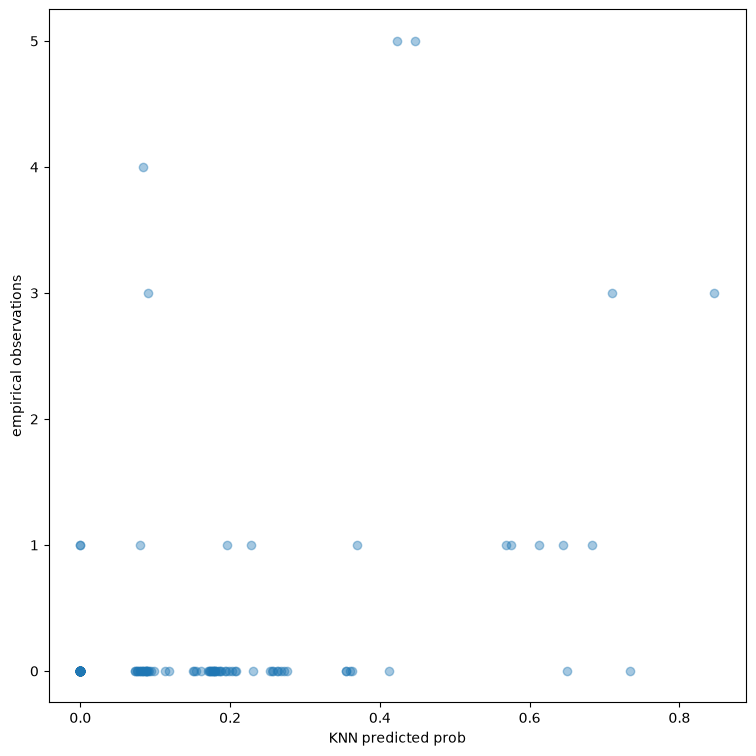

In [46]:
# I wonder if it would be better to separate distance in the statistic model.
fig, ax = plt.subplots(figsize = (9,9))
plt.scatter(df_validation["predict_proba"], df_validation["empirical"], alpha = 0.4)
ax.set_xlabel("KNN predicted prob")
ax.set_ylabel("empirical observations")